# CU-BEMS Smart Building — Floor 1 EDA

**Owner:** Leyna · **Scope:** `data/raw/2018Floor1.csv` (Jul–Dec 2018) + `data/raw/2019Floor1.csv` (Jan–Dec 2019)

**Dataset:** CU-BEMS Smart Building Energy & Indoor Environmental Data (Kaggle) — 1-minute sampling.

Outline:
1. Setup & load
2. Structure, schema & timestamp continuity
3. Missing data
4. Outliers, spikes & dead channels
5. Cleaning rules (applied to a copy)
6. Energy consumption over time
7. Daily / weekly patterns
8. Zone & end-use breakdown
9. HVAC (AC) behaviour
10. Year-over-year shifts
11. Correlations
12. Findings summary & next steps

> **Reading the code:** every cell is commented. `raw` = the data exactly as loaded; `df` = the cleaned copy (from section 5 on).

## 1. Setup & load

In [1]:
# --- Libraries ---
import pandas as pd                 # tables (DataFrames) and time-series handling
import numpy as np                  # numerical helpers (arrays, np.where, etc.)
import matplotlib.pyplot as plt     # plotting
import matplotlib.dates as mdates   # nicer date labels on plot x-axes
import os                           # building file paths that work on Windows and Mac

# Show all columns when printing a DataFrame, and use a wide display so tables don't wrap
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

# One fixed colour per end-use so Light/Plug/AC look the same in every chart
C = {'Light': '#2a78d6', 'Plug': '#eb6834', 'AC': '#1baf7a', 'Total': '#52514e'}

# Default chart style: standard size, no top/right border lines, faint grid, thin lines
plt.rcParams.update({
    'figure.figsize': (12, 4), 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.2,
})

In [2]:
DATA_DIR = '../data/raw'   # raw CSVs sit in data/raw/, one folder up from eda/
FILES = {2018: '2018Floor1.csv', 2019: '2019Floor1.csv'}   # year -> file name

frames = []                                   # we'll collect one DataFrame per year here
for year, fname in FILES.items():
    # Read the CSV; parse_dates turns the 'Date' text column into real datetime values
    d = pd.read_csv(os.path.join(DATA_DIR, fname), parse_dates=['Date'])
    d['year'] = year                          # tag each row with its source year (handy for filtering)
    frames.append(d)
    print(f"{fname}: {d.shape[0]:,} rows × {d.shape[1]-1} cols")   # -1 so the added 'year' col isn't counted

# Sanity check: both years must have identical columns, otherwise stacking them would misalign data
assert list(frames[0].columns) == list(frames[1].columns), 'column mismatch between years'

# Stack 2018 on top of 2019, make the timestamp the row index (enables time-based slicing/resampling), sort by time
raw = pd.concat(frames, ignore_index=True).set_index('Date').sort_index()

# All meter columns end in '(kW)' — keep that list so we don't accidentally include 'year' in calculations
POWER_COLS = [c for c in raw.columns if c.endswith('(kW)')]
print('\nCombined:', raw.shape)
print('Power columns:', POWER_COLS)
raw.head()   # show the first 5 rows

2018Floor1.csv: 264,960 rows × 12 cols
2019Floor1.csv: 525,600 rows × 12 cols

Combined: (790560, 12)
Power columns: ['z1_Light(kW)', 'z1_Plug(kW)', 'z2_AC1(kW)', 'z2_AC2(kW)', 'z2_AC3(kW)', 'z2_AC4(kW)', 'z2_Light(kW)', 'z2_Plug(kW)', 'z3_Light(kW)', 'z3_Plug(kW)', 'z4_Light(kW)']


,z1_Light(kW),z1_Plug(kW),z2_AC1(kW),z2_AC2(kW),z2_AC3(kW),z2_AC4(kW),z2_Light(kW),z2_Plug(kW),z3_Light(kW),z3_Plug(kW),z4_Light(kW),year
Date,,,,,,,,,,,,
2018-07-01 00:00:00,12.94,18.56,45.24,0.01,0.01,0.00,13.76,17.64,10.92,0.89,35.76,2018
2018-07-01 00:01:00,12.97,18.55,45.28,0.02,0.01,0.01,13.76,17.21,10.95,0.87,35.81,2018
2018-07-01 00:02:00,12.97,18.55,45.24,0.01,0.01,0.01,13.79,17.18,10.94,0.86,35.78,2018
2018-07-01 00:03:00,12.98,18.58,45.26,0.02,0.01,0.00,13.81,16.64,10.94,0.85,35.83,2018
2018-07-01 00:04:00,13.01,18.60,45.22,0.02,0.01,0.01,13.83,15.69,10.97,0.85,35.86,2018


## 2. Structure, schema & timestamp continuity

Column naming is `z<zone>_<end-use>(kW)`. Floor 1 has **power meters only** — no temperature, humidity or lux
sensors (unlike some other floors), so indoor-environment questions can't be answered from Floor 1 alone.

In [3]:
# Break each column name like 'z2_AC1(kW)' into its parts so we can group meters later
schema = pd.DataFrame({
    'zone':    [c.split('_')[0] for c in POWER_COLS],                      # 'z2'
    'end_use': [c.split('_')[1].replace('(kW)', '') for c in POWER_COLS],  # 'AC1'
}, index=POWER_COLS)

# 'category' drops the unit number, so AC1..AC4 all become 'AC' (Light and Plug are unchanged)
schema['category'] = schema['end_use'].str.replace(r'\d+', '', regex=True)

print(raw[POWER_COLS].dtypes.value_counts())   # confirm every meter column is numeric (float64)
schema

float64    11
Name: count, dtype: int64


,zone,end_use,category
z1_Light(kW),z1,Light,Light
z1_Plug(kW),z1,Plug,Plug
z2_AC1(kW),z2,AC1,AC
z2_AC2(kW),z2,AC2,AC
z2_AC3(kW),z2,AC3,AC
z2_AC4(kW),z2,AC4,AC
z2_Light(kW),z2,Light,Light
z2_Plug(kW),z2,Plug,Plug
z3_Light(kW),z3,Light,Light
z3_Plug(kW),z3,Plug,Plug


In [4]:
# Zone × end-use matrix: a 1 means that meter exists in that zone
pd.crosstab(schema['zone'], schema['end_use'])

end_use,AC1,AC2,AC3,AC4,Light,Plug
zone,,,,,,
z1,0,0,0,0,1,1
z2,1,1,1,1,1,1
z3,0,0,0,0,1,1
z4,0,0,0,0,1,0


In [5]:
# Timestamp continuity: data is meant to be one row per minute with no duplicates or skipped minutes
idx = raw.index
expected = pd.date_range(idx.min(), idx.max(), freq='1min')   # every minute that SHOULD exist
print('Range            :', idx.min(), '→', idx.max())
print('Rows             :', f'{len(idx):,}')
print('Expected minutes :', f'{len(expected):,}')
print('Duplicate stamps :', idx.duplicated().sum())                  # same minute appearing twice
print('Missing stamps   :', len(expected.difference(idx)))           # minutes with no row at all
print('Step sizes       :', idx.to_series().diff().value_counts().to_dict())   # gap between consecutive rows

Range            : 2018-07-01 00:00:00 → 2019-12-31 23:59:00
Rows             : 790,560
Expected minutes : 790,560
Duplicate stamps : 0
Missing stamps   : 0
Step sizes       : {Timedelta('0 days 00:01:00'): 790559}


> ✅ The timeline is **perfectly regular** — 1-minute steps, no duplicate or missing timestamps across 18 months.
> Gaps in the data show up as `NaN` values, not as missing rows.

In [6]:
# Summary statistics per meter. Extra percentiles (1%, 99%, 99.9%) help spot extreme values:
# if 'max' is far above '99.9%', the meter probably has a few bad readings.
# .T flips the table so each meter is a row (easier to read).
raw[POWER_COLS].describe(percentiles=[.01, .25, .5, .75, .99, .999]).T.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,99.9%,max
z1_Light(kW),788169.0,6.37,8.58,0.0,0.00,0.01,0.02,12.22,42.83,46.50,134.97
z1_Plug(kW),789459.0,2.43,4.69,0.0,0.00,0.57,0.72,1.19,19.53,26.38,57.86
z2_AC1(kW),788231.0,28.04,22.24,0.0,0.02,0.03,44.14,46.88,52.01,56.92,131.55
z2_AC2(kW),788355.0,5.10,12.80,0.0,0.01,0.02,0.02,0.03,40.33,44.49,798.72
z2_AC3(kW),788354.0,0.01,0.03,0.0,0.00,0.01,0.01,0.01,0.02,0.02,24.95
z2_AC4(kW),788354.0,0.01,0.01,0.0,0.00,0.00,0.01,0.01,0.03,0.03,0.06
z2_Light(kW),788516.0,10.33,4.51,0.0,4.08,6.98,9.04,14.09,19.63,31.38,55.28
z2_Plug(kW),760031.0,15.13,3.71,0.0,7.24,13.07,15.09,17.14,26.47,38.02,73.68
z3_Light(kW),789447.0,21.82,13.52,0.0,5.43,12.91,19.13,26.11,65.95,93.27,4762.43
z3_Plug(kW),788355.0,1.20,0.67,0.0,0.38,0.81,0.98,1.70,2.66,4.72,22.22


## 3. Missing data

In [7]:
# % of minutes missing (NaN) for each meter, calculated separately for each year.
# .isna() gives True/False per cell; the mean of True/False = share of True; ×100 makes it a percentage.
miss = pd.DataFrame({
    y: raw.loc[raw.year == y, POWER_COLS].isna().mean() * 100 for y in FILES
}).round(2)
miss.columns = [f'{y} % missing' for y in FILES]
miss['overall % missing'] = (raw[POWER_COLS].isna().mean() * 100).round(2)
miss.sort_values('overall % missing', ascending=False)   # worst meter at the top

,2018 % missing,2019 % missing,overall % missing
z2_Plug(kW),11.26,0.13,3.86
z1_Light(kW),0.55,0.18,0.30
z2_AC1(kW),0.57,0.15,0.29
z2_AC2(kW),0.55,0.14,0.28
z2_AC3(kW),0.55,0.14,0.28
z2_AC4(kW),0.55,0.14,0.28
z3_Plug(kW),0.55,0.14,0.28
z2_Light(kW),0.54,0.12,0.26
z1_Plug(kW),0.18,0.12,0.14
z3_Light(kW),0.19,0.11,0.14


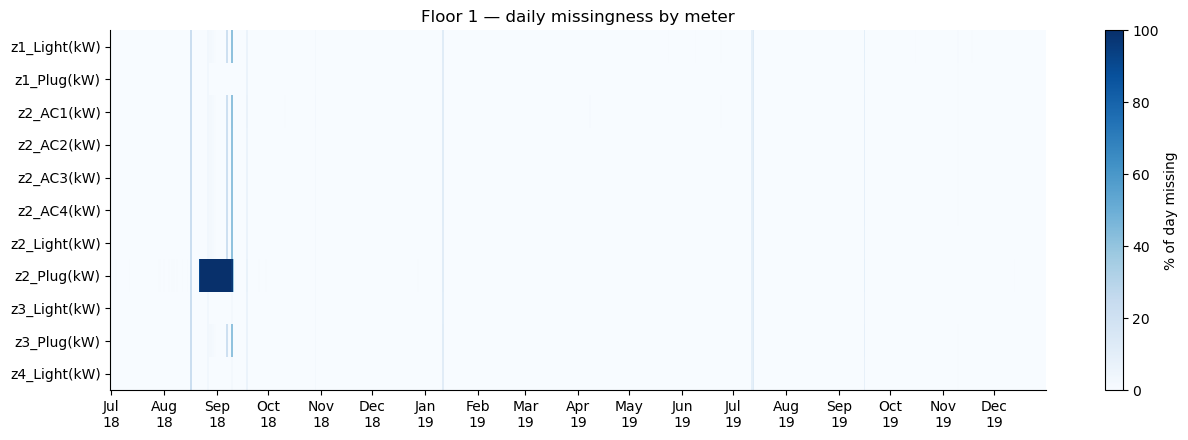

In [8]:
# Missingness over time: for each day and each meter, what % of that day's minutes are missing?
daily_miss = raw[POWER_COLS].isna().resample('D').mean() * 100   # resample('D') = group by calendar day

fig, ax = plt.subplots(figsize=(13, 4.5))
# imshow draws the table as a heatmap: rows = meters, columns = days, darker = more missing
im = ax.imshow(daily_miss.T.values, aspect='auto', cmap='Blues', vmin=0, vmax=100, interpolation='nearest')
ax.set_yticks(range(len(POWER_COLS)), POWER_COLS)
ticks = np.where(daily_miss.index.day == 1)[0]    # put an x-axis label on the 1st of each month
ax.set_xticks(ticks, daily_miss.index[ticks].strftime('%b\n%y'), rotation=0)
ax.grid(False)                                    # gridlines look messy on a heatmap
fig.colorbar(im, ax=ax, label='% of day missing')
ax.set_title('Floor 1 — daily missingness by meter')
plt.tight_layout(); plt.show()

In [9]:
# Find outage "blocks": consecutive minutes where EVERY meter is NaN (i.e. the whole logger was down)
all_na = raw[POWER_COLS].isna().all(axis=1)          # True for a minute if all meters are missing

# Trick to label consecutive runs: the id increases by 1 every time the value flips True<->False,
# so each unbroken stretch of True (or False) gets its own number
block_id = (all_na != all_na.shift()).cumsum()

# Keep only the True runs, and for each one record when it started, ended, and how many minutes it lasted
blocks = (all_na[all_na].groupby(block_id[all_na])
          .agg(start=lambda s: s.index.min(), end=lambda s: s.index.max(), minutes='size'))
print(f'Rows with ALL meters missing: {all_na.sum():,}  in {len(blocks)} blocks')
blocks.sort_values('minutes', ascending=False).head(10).reset_index(drop=True)   # 10 longest outages

Rows with ALL meters missing: 1,067  in 67 blocks


,start,end,minutes
0,2018-08-17 06:53:00,2018-08-17 12:10:00,318
1,2019-07-12 21:46:00,2019-07-13 02:14:00,269
2,2018-09-19 13:03:00,2018-09-19 14:28:00,86
3,2019-01-12 08:11:00,2019-01-12 09:32:00,82
4,2019-07-13 02:23:00,2019-07-13 03:18:00,56
5,2019-09-16 11:30:00,2019-09-16 12:13:00,44
6,2019-01-12 07:43:00,2019-01-12 08:09:00,27
7,2018-10-29 04:59:00,2018-10-29 05:21:00,23
8,2019-09-16 12:19:00,2019-09-16 12:38:00,20
9,2019-09-16 12:56:00,2019-09-16 13:12:00,17


In [10]:
# z2_Plug has much more missing data in 2018 than anything else. Same run-labelling trick as above,
# but for this single meter, to find where its long outage is
z2p = raw['z2_Plug(kW)'].isna()
bid = (z2p != z2p.shift()).cumsum()
z2p_blocks = (z2p[z2p].groupby(bid[z2p])
              .agg(start=lambda s: s.index.min(), end=lambda s: s.index.max(), minutes='size'))
# Show the 3 longest gaps, with length converted to days (1440 minutes per day)
z2p_blocks.sort_values('minutes', ascending=False).head(3).assign(days=lambda d: (d.minutes / 1440).round(1))

,start,end,minutes,days
z2_Plug(kW),,,,
366,2018-08-22 02:28:00,2018-09-10 14:13:00,28066,19.5
368,2018-09-10 14:57:00,2018-09-11 08:39:00,1063,0.7
338,2018-08-17 06:53:00,2018-08-17 12:12:00,320,0.2


**Missing-data takeaways**
- Overall missingness is low (<0.6% for most meters).
- **`z2_Plug` is the exception in 2018 (~11%)**: one continuous ~20-day outage from **22 Aug to 11 Sep 2018** — other meters kept reporting.
- The rest are short, logger-wide outages (all meters NaN together); the biggest are ~5 h on 17 Aug 2018 and ~4.5 h on 12 Jul 2019.
- Short gaps (≤ a few hours) can be safely time-interpolated; the 20-day z2_Plug hole should **not** be interpolated — leave it NaN or exclude that window for z2_Plug analyses.

## 4. Outliers, spikes & dead channels

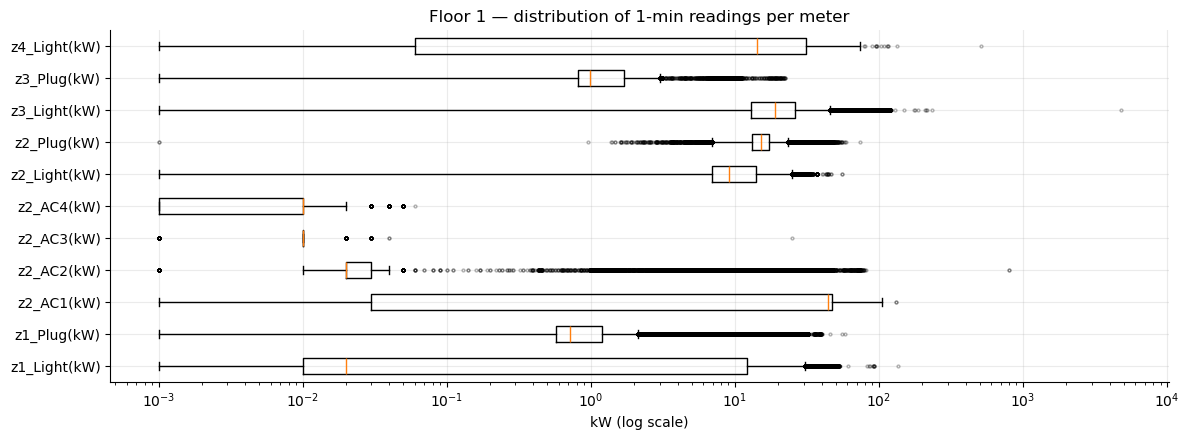

In [11]:
# Box plot of every meter's readings, to see the typical range and the outliers (the dots).
# Log scale is needed because values range from 0.01 kW (idle AC units) to 4,000+ kW (glitches).
fig, ax = plt.subplots(figsize=(12, 4.5))
data = [raw[c].dropna().clip(lower=1e-3) for c in POWER_COLS]   # clip 0 → 0.001 because log(0) is undefined
ax.boxplot(data, vert=False, tick_labels=POWER_COLS, showfliers=True, flierprops=dict(markersize=2, alpha=.3))
ax.set_xscale('log'); ax.set_xlabel('kW (log scale)')
ax.set_title('Floor 1 — distribution of 1-min readings per meter')
plt.tight_layout(); plt.show()

In [12]:
# The 3 largest readings for each meter, with the exact timestamp, so we can judge if they're real or glitches.
top = (raw[POWER_COLS].stack().rename('kW').reset_index()     # stack(): wide table -> long list of (Date, meter, value)
       .rename(columns={'level_1': 'meter'})
       .sort_values('kW', ascending=False)                    # biggest first
       .groupby('meter').head(3)                              # keep the top 3 per meter
       .sort_values(['meter', 'kW'], ascending=[True, False]))
top

,Date,meter,kW
947248,2018-08-30 21:30:00,z1_Light(kW),134.97
945950,2018-08-30 19:16:00,z1_Light(kW),93.12
947584,2018-08-30 22:05:00,z1_Light(kW),92.75
947249,2018-08-30 21:30:00,z1_Plug(kW),57.86
950073,2018-08-31 02:18:00,z1_Plug(kW),55.71
918816,2018-08-28 21:37:00,z1_Plug(kW),45.84
947250,2018-08-30 21:30:00,z2_AC1(kW),131.55
950074,2018-08-31 02:18:00,z2_AC1(kW),130.57
3737482,2019-02-24 16:38:00,z2_AC1(kW),104.48
1092848,2018-09-10 10:47:00,z2_AC2(kW),798.72


Some maxima are physically implausible **single-minute glitches**, e.g. `z3_Light` = 4,762 kW (median ≈ 20 kW),
`z2_AC2` = 798 kW (normal max ≈ 80), `z4_Light` = 512 kW, `z2_AC3` = 25 kW on a meter that otherwise reads 0.01.

Rule used to flag spikes: a reading is a spike if it is **more than 3× the meter's 99.9th percentile _and_ the excursion
lasts ≤ 3 minutes _and_ the surrounding 31-minute median is normal (< cap/3)**. The duration condition matters: `z3_Plug` has sustained multi-minute runs at 15–20 kW (a real device
switching on), which a pure threshold would wrongly delete.

In [13]:
# --- Spike detection. A reading counts as a spike only if ALL three conditions hold. ---

# Condition 1: the value is more than 3× the meter's 99.9th percentile (i.e. far above its normal maximum)
q999 = raw[POWER_COLS].quantile(0.999)
SPIKE_CAP = (3 * q999).clip(lower=1.0)   # minimum cap of 1 kW, so near-zero meters (AC3/AC4) aren't over-flagged
exceed = raw[POWER_COLS].gt(SPIKE_CAP)   # True where a reading is above its meter's cap

# Condition 2: the excursion is short (≤ 3 consecutive minutes). A real device switching on stays high for longer.
def short_runs(m, max_len=3):
    run_id = (m != m.shift()).cumsum()                                  # label consecutive True/False runs
    return m & (m.groupby(run_id).transform('size') <= max_len)         # keep only True runs of length ≤ max_len

# Condition 3: the surrounding 31-min median is normal (below cap/3), so brief crossings of the cap
# during a genuine high-load period are kept
context_ok = raw[POWER_COLS].rolling('31min', center=True).median().lt(SPIKE_CAP / 3)

spikes = exceed.apply(short_runs) & context_ok   # final True/False table: True = spike, remove it

print('Spike cap per meter (kW):'); print(SPIKE_CAP.round(1).to_string())
print()
# Compare how many readings were above the cap vs how many the full rule actually flags
print(pd.DataFrame({'above cap': exceed.sum(), 'flagged as spike': spikes.sum()})[lambda d: d['above cap'] > 0].to_string())
raw.loc[spikes.any(axis=1), POWER_COLS].round(2)   # show every minute that contains at least one flagged spike

Spike cap per meter (kW):
z1_Light(kW)    139.5
z1_Plug(kW)      79.1
z2_AC1(kW)      170.8
z2_AC2(kW)      133.5
z2_AC3(kW)        1.0
z2_AC4(kW)        1.0
z2_Light(kW)     94.1
z2_Plug(kW)     114.1
z3_Light(kW)    279.8
z3_Plug(kW)      14.2
z4_Light(kW)    186.4

              above cap  flagged as spike
z2_AC2(kW)            2                 2
z2_AC3(kW)            1                 1
z3_Light(kW)          1                 1
z3_Plug(kW)          93                 2
z4_Light(kW)          1                 1


,z1_Light(kW),z1_Plug(kW),z2_AC1(kW),z2_AC2(kW),z2_AC3(kW),z2_AC4(kW),z2_Light(kW),z2_Plug(kW),z3_Light(kW),z3_Plug(kW),z4_Light(kW)
Date,,,,,,,,,,,
2018-09-07 15:50:00,0.00,0.00,NaN,0.00,24.95,0.00,0.00,NaN,6.60,0.00,512.01
2018-09-10 10:46:00,NaN,0.00,NaN,798.70,0.00,0.00,0.00,NaN,8.06,0.00,0.01
2018-09-10 10:47:00,0.00,0.01,NaN,798.72,0.00,0.00,0.00,NaN,8.07,0.00,0.01
2018-09-11 09:54:00,0.02,2.35,0.03,0.02,0.01,0.00,13.91,5.44,4762.43,1.88,8.24
2019-08-25 08:05:00,0.01,2.40,52.65,0.03,0.00,0.01,12.45,11.61,10.62,15.72,0.07
2019-08-25 08:06:00,0.01,11.94,48.33,0.03,0.01,0.00,12.45,11.61,10.61,14.66,0.04


In [14]:
# Dead / idle channels: what % of the time does each meter read almost nothing (< 0.1 kW)?
# A meter near 100% here is never actually used.
idle_share = (raw[POWER_COLS] < 0.1).mean().mul(100).round(1).sort_values(ascending=False)
pd.DataFrame({'% of minutes < 0.1 kW': idle_share,
              # highest reading once spikes are ignored (.where(~spikes) hides the spike values)
              'max kW (after spike cap)': raw[POWER_COLS].where(~spikes).max().round(2)})

,% of minutes < 0.1 kW,max kW (after spike cap)
z1_Light(kW),54.5,134.97
z1_Plug(kW),21.3,57.86
z2_AC1(kW),26.2,131.55
z2_AC2(kW),81.0,80.92
z2_AC3(kW),99.7,0.04
z2_AC4(kW),99.7,0.06
z2_Light(kW),0.0,55.28
z2_Plug(kW),0.0,73.68
z3_Light(kW),0.0,232.71
z3_Plug(kW),0.0,22.22


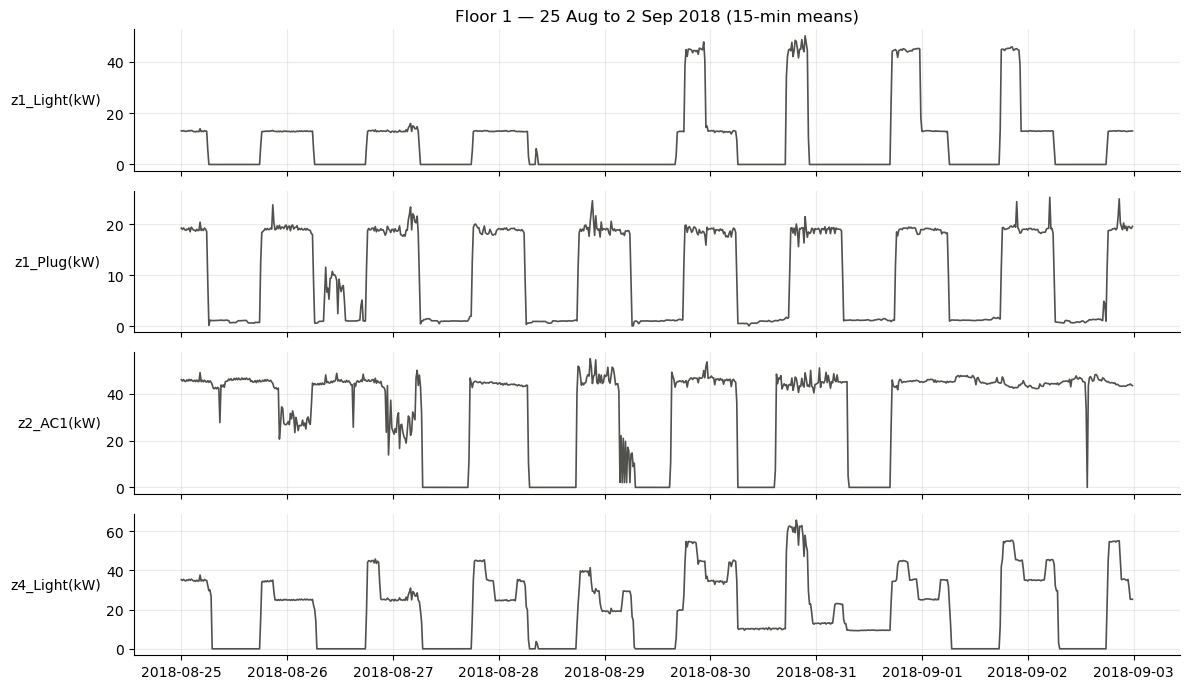

In [15]:
# Late Aug 2018 looks unusual across several meters at once, so zoom in on that week
# .loc['start':'end'] slices by date; resample('15min').mean() averages into 15-min buckets to smooth the plot
win = raw.loc['2018-08-25':'2018-09-02', ['z1_Light(kW)', 'z1_Plug(kW)', 'z2_AC1(kW)', 'z4_Light(kW)']].resample('15min').mean()

# One small chart per meter, stacked vertically, sharing the same time axis
fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for ax, col in zip(axes, win.columns):
    ax.plot(win.index, win[col], color=C['Total'])
    ax.set_ylabel(col, rotation=0, ha='right', va='center')   # horizontal label, easier to read
axes[0].set_title('Floor 1 — 25 Aug to 2 Sep 2018 (15-min means)')
plt.tight_layout(); plt.show()

**Outlier takeaways**
- **`z2_AC3` and `z2_AC4` are effectively dead** — ~0.01 kW nearly 100% of the time (standby/meter noise). Treat them as
  unused units; drop them from modelling (they carry no signal) but keep them in totals (negligible).
- A handful of **single-minute spikes** (e.g. 4,762 kW, 798 kW) are sensor glitches → set to NaN.
- **28–31 Aug 2018** shows simultaneous, sustained high readings on lighting, z1_Plug and AC1 — including overnight.
  It's multi-hour and consistent across meters, so it looks like a **real event** (e.g. an event / after-hours use of the space)
  rather than noise. Kept in the data, but worth flagging when building a baseline.

## 5. Cleaning rules (applied to a copy)

1. Spikes (flagged in section 4) → NaN
2. Short gaps (≤ 60 min) → time interpolation
3. Longer gaps stay NaN (notably the 20-day z2_Plug outage)
4. Derived columns: category totals (Light / Plug / AC) and floor total, in kW. Energy in kWh = mean kW × hours.

In [16]:
df = raw.copy()                                        # work on a copy so `raw` stays untouched for comparison

df[POWER_COLS] = df[POWER_COLS].mask(spikes)          # mask(): replace every flagged spike with NaN

# Fill short gaps by drawing a straight line between the readings on either side.
#   limit=60           -> fill at most 60 consecutive missing minutes (longer outages stay NaN)
#   limit_area='inside' -> only fill gaps that have real data on both sides
df[POWER_COLS] = df[POWER_COLS].interpolate(method='time', limit=60, limit_area='inside')

print('NaNs before cleaning:', int(raw[POWER_COLS].isna().sum().sum()))
print('NaNs after  cleaning:', int(df[POWER_COLS].isna().sum().sum()))

# Build a dict of category -> list of its meters, e.g. {'AC': ['z2_AC1(kW)', ..., 'z2_AC4(kW)'], ...}
cat_cols = {cat: schema.index[schema.category == cat].tolist() for cat in ['Light', 'Plug', 'AC']}

# New columns: total kW per category. min_count=len(cols) makes the sum NaN if ANY meter in the group is
# missing, so a total is never silently too low because one part is missing.
for cat, cols in cat_cols.items():
    df[cat] = df[cols].sum(axis=1, min_count=len(cols))
df['Total'] = df[['Light', 'Plug', 'AC']].sum(axis=1, min_count=3)   # whole-floor total kW
cat_cols

NaNs before cleaning: 49456
NaNs after  cleaning: 40819


{'Light': ['z1_Light(kW)', 'z2_Light(kW)', 'z3_Light(kW)', 'z4_Light(kW)'],
 'Plug': ['z1_Plug(kW)', 'z2_Plug(kW)', 'z3_Plug(kW)'],
 'AC': ['z2_AC1(kW)', 'z2_AC2(kW)', 'z2_AC3(kW)', 'z2_AC4(kW)']}

## 6. Energy consumption over time

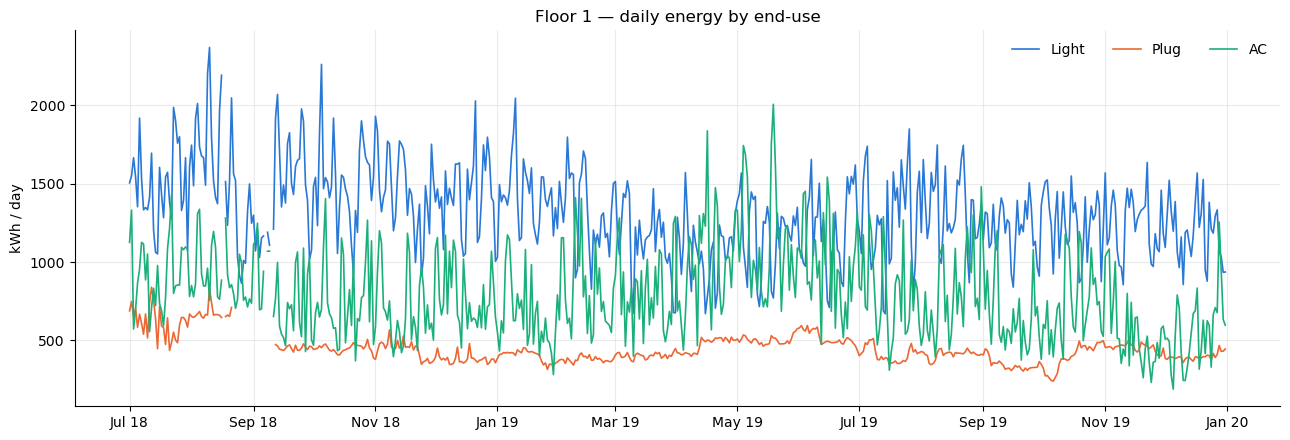

In [17]:
# Convert power (kW) into daily energy (kWh): average kW over the day × 24 hours.
# If more than 10% of a day's minutes are missing, return NaN for that day instead of an average that's too low.
def daily_kwh(s):
    ok = s.notna().resample('D').mean() >= 0.9          # True for days with ≥ 90% of minutes present
    return (s.resample('D').mean() * 24).where(ok)      # .where(ok) sets the other days to NaN

daily = pd.DataFrame({c: daily_kwh(df[c]) for c in ['Light', 'Plug', 'AC', 'Total']})

# One line per end-use across the full 18 months
fig, ax = plt.subplots(figsize=(13, 4.5))
for c in ['Light', 'Plug', 'AC']:
    ax.plot(daily.index, daily[c], color=C[c], label=c)
ax.set_ylabel('kWh / day'); ax.legend(frameon=False, ncol=3, loc='upper right')
ax.set_title('Floor 1 — daily energy by end-use')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))   # x labels like 'Jul 18'
plt.tight_layout(); plt.show()

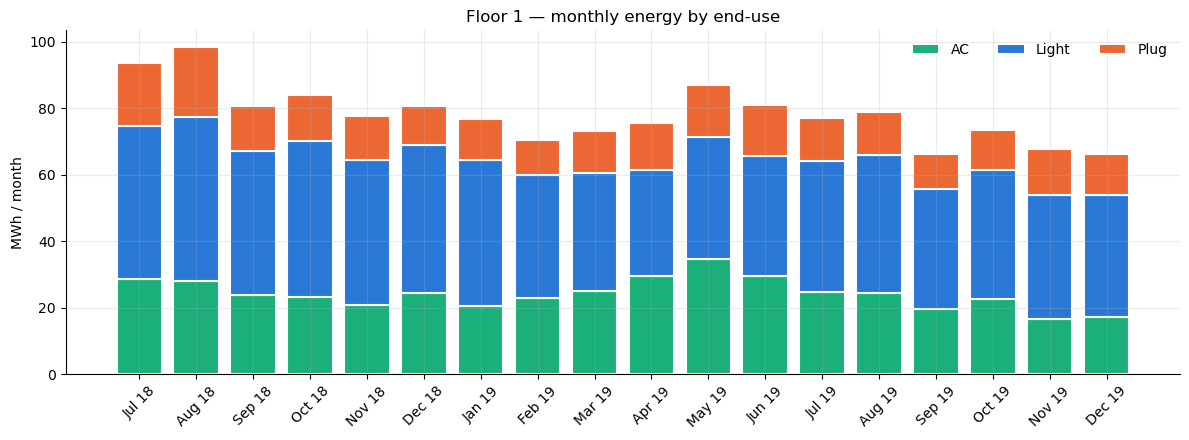

Date,2018-07-01,2018-08-01,2018-09-01,2018-10-01,2018-11-01,2018-12-01,2019-01-01,2019-02-01,2019-03-01,2019-04-01,2019-05-01,2019-06-01,2019-07-01,2019-08-01,2019-09-01,2019-10-01,2019-11-01,2019-12-01
Light,46.11,49.37,43.05,46.73,43.59,44.42,43.86,36.93,35.54,31.97,36.58,36.06,39.66,41.36,36.20,38.69,37.35,36.78
Plug,19.05,20.99,13.62,13.93,13.24,11.84,12.43,10.62,12.52,14.11,15.57,15.53,12.73,12.78,10.37,12.18,13.68,12.31
AC,28.53,28.14,23.98,23.31,20.76,24.46,20.53,22.96,25.06,29.46,34.77,29.49,24.61,24.57,19.58,22.61,16.69,17.24
Total,93.69,98.50,80.65,83.97,77.59,80.72,76.82,70.51,73.13,75.54,86.91,81.08,77.00,78.72,66.15,73.48,67.72,66.34


In [18]:
# Monthly energy in MWh = mean kW for the month × 24 h × days in the month ÷ 1000
# ('MS' = group by month, labelled by the month's start date; the minute count ÷ 1440 gives days in the month)
monthly = (df[['Light', 'Plug', 'AC']].resample('MS').mean() * 24 *
           df.index.to_series().resample('MS').count().div(1440).values[:, None]) / 1000

# Stacked bar chart: draw AC first, then Light on top of it, then Plug on top of that
fig, ax = plt.subplots(figsize=(12, 4.5))
bottom = np.zeros(len(monthly))                  # running height where the next layer starts
for c in ['AC', 'Light', 'Plug']:
    ax.bar(monthly.index.strftime('%b %y'), monthly[c], bottom=bottom, color=C[c], label=c,
           edgecolor='white', linewidth=1.5)     # thin white edge separates the stacked layers
    bottom += monthly[c].values                  # raise the base for the next layer
ax.set_ylabel('MWh / month'); ax.legend(frameon=False, ncol=3)
ax.set_title('Floor 1 — monthly energy by end-use')
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
monthly.assign(Total=monthly.sum(axis=1)).round(2).T   # same numbers as a table, with a Total row

## 7. Daily / weekly patterns

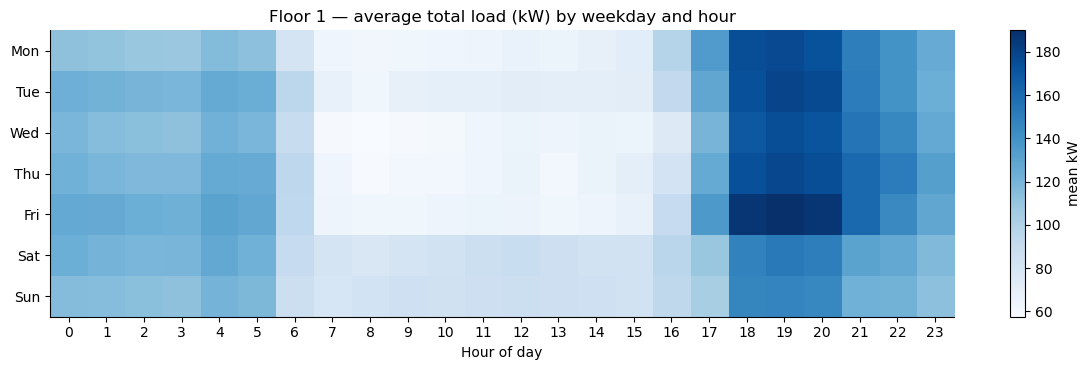

In [19]:
# Average whole-floor load for each (weekday, hour) combination, e.g. "Mondays at 9am"
tmp = df[['Total']].copy()
tmp['dow'] = tmp.index.dayofweek      # 0 = Monday ... 6 = Sunday
tmp['hour'] = tmp.index.hour          # 0..23
heat = tmp.pivot_table(index='dow', columns='hour', values='Total', aggfunc='mean')   # 7 × 24 table of means

# Draw that 7 × 24 table as a heatmap: darker = higher load
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(heat.values, aspect='auto', cmap='Blues')
ax.set_yticks(range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax.set_xticks(range(24)); ax.set_xlabel('Hour of day'); ax.grid(False)
fig.colorbar(im, ax=ax, label='mean kW')
ax.set_title('Floor 1 — average total load (kW) by weekday and hour')
plt.tight_layout(); plt.show()

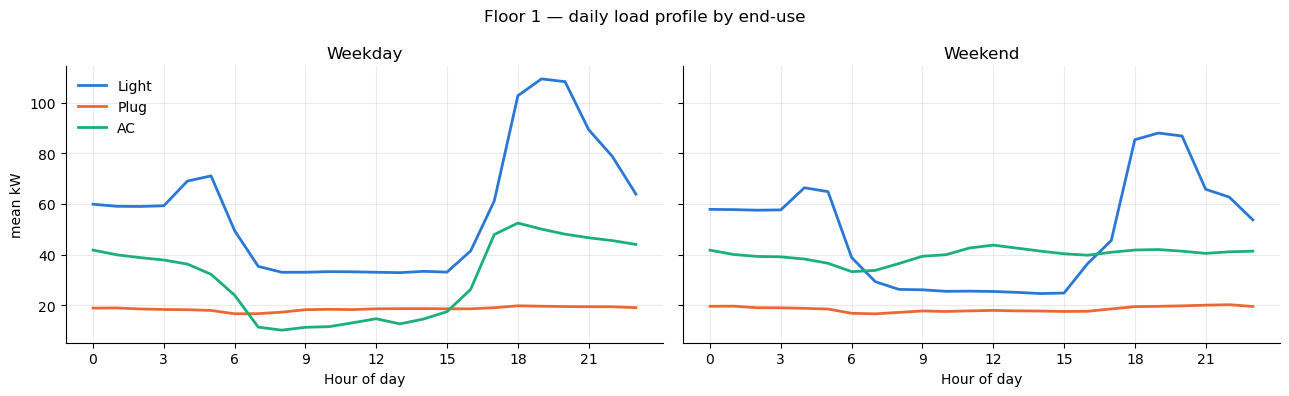

In [20]:
# Typical 24-hour load curve for each end-use, weekdays and weekends plotted separately
tmp = df[['Light', 'Plug', 'AC']].copy()
tmp['hour'] = tmp.index.hour
tmp['daytype'] = np.where(tmp.index.dayofweek >= 5, 'Weekend', 'Weekday')   # Sat(5)/Sun(6) = weekend
prof = tmp.groupby(['daytype', 'hour']).mean()     # mean kW for each (daytype, hour)

# Two panels side by side with the same y-axis so they're directly comparable
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, dt in zip(axes, ['Weekday', 'Weekend']):
    for c in ['Light', 'Plug', 'AC']:
        ax.plot(prof.loc[dt].index, prof.loc[dt][c], color=C[c], label=c, linewidth=2)
    ax.set_title(dt); ax.set_xlabel('Hour of day'); ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel('mean kW'); axes[0].legend(frameon=False)
fig.suptitle('Floor 1 — daily load profile by end-use')
plt.tight_layout(); plt.show()

In [21]:
# Compare working-hours load with night-time load
work = df.between_time('09:00', '17:00')     # rows between 09:00 and 17:00 (any day)
night = df.between_time('00:00', '05:00')    # rows between midnight and 05:00
wk = work[work.index.dayofweek < 5]          # working hours on weekdays only

# Mean kW in each window, plus the ratio night ÷ day (a normal office should be well below 1)
pd.DataFrame({'weekday 09–17 mean kW': wk[['Light', 'Plug', 'AC', 'Total']].mean(),
              'night 00–05 mean kW': night[['Light', 'Plug', 'AC', 'Total']].mean()}).round(1) \
  .assign(**{'night / day ratio': lambda d: (d.iloc[:, 1] / d.iloc[:, 0]).round(2)})

,weekday 09–17 mean kW,night 00–05 mean kW,night / day ratio
Light,34.2,60.8,1.78
Plug,18.6,18.8,1.01
AC,15.3,39.2,2.56
Total,68.4,118.8,1.74


⚠️ **This profile is inverted relative to a normal office**: load is *lowest* 07:00–15:00 on weekdays and peaks 18:00–20:00,
and the night (00–05) average is higher than the working-hours average. On weekends daytime AC is *higher* than on weekdays.
Either Floor 1 is genuinely used at night, or **the timestamps are offset**. The building is in Bangkok (UTC+7), so a
timezone shift is the obvious suspect — test it below.

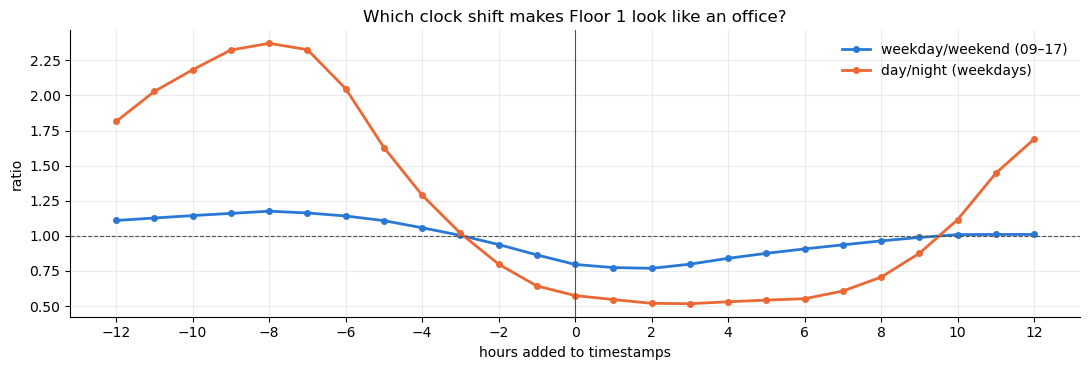

,weekday/weekend (09–17),day/night (weekdays)
shift_h,,
-8,1.18,2.37
-7,1.16,2.33
-6,1.14,2.05
0,0.80,0.57


In [22]:
# Timestamp-offset test: pretend the clock is off by s hours, then check whether the data looks like an office.
# Two 'office-ness' signals:
#   1) weekday ÷ weekend load during 09–17   (a real office → above 1: busier on weekdays)
#   2) weekday 09–17 ÷ weekday 00–05 load    (a real office → well above 1: busier by day than at night)
tot = df['Total'].dropna()
rows = []
for s in range(-12, 13):                              # try every shift from −12 h to +12 h
    idx = tot.index + pd.Timedelta(hours=s)           # shifted timestamps (the data itself is unchanged)
    h, wd = idx.hour, idx.dayofweek < 5               # hour of day and is-weekday, using the shifted clock
    work, night = (h >= 9) & (h < 17), h < 5          # True/False masks for working hours and night
    rows.append({'shift_h': s,
                 'weekday/weekend (09–17)': tot[work & wd].mean() / tot[work & ~wd].mean(),
                 'day/night (weekdays)':   tot[work & wd].mean() / tot[night & wd].mean()})
shift_test = pd.DataFrame(rows).set_index('shift_h')

# Plot both ratios against the shift; the best shift is where both are clearly above 1
fig, ax = plt.subplots(figsize=(11, 3.8))
for col, colour in zip(shift_test.columns, [C['Light'], C['Plug']]):
    ax.plot(shift_test.index, shift_test[col], color=colour, linewidth=2, marker='o', markersize=4, label=col)
ax.axhline(1, color='#52514e', linewidth=.8, linestyle='--')   # ratio = 1 reference line
ax.axvline(0, color='#52514e', linewidth=.8)                   # 'no shift' reference line
ax.set_xticks(range(-12, 13, 2)); ax.set_xlabel('hours added to timestamps'); ax.set_ylabel('ratio')
ax.legend(frameon=False); ax.set_title('Which clock shift makes Floor 1 look like an office?')
plt.tight_layout(); plt.show()
shift_test.round(2).loc[[-8, -7, -6, 0]]   # show the most interesting rows as numbers

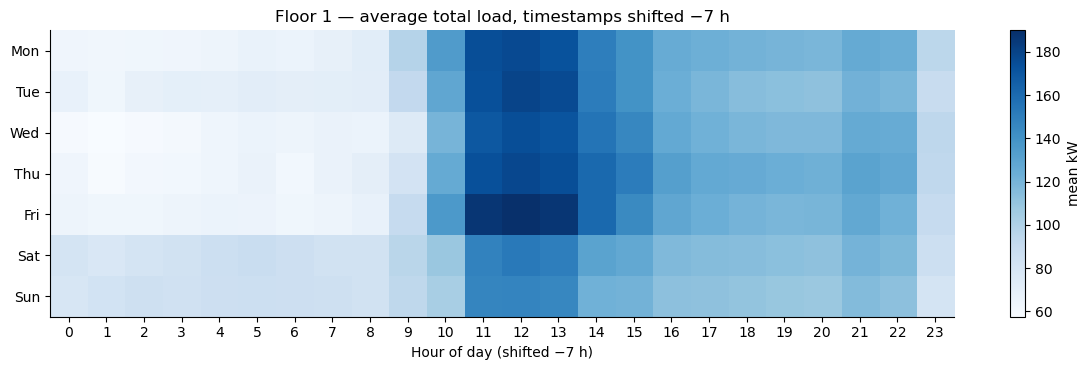

In [23]:
# Redraw the weekday × hour heatmap with the clock shifted back 7 h (the UTC+7 hypothesis), to compare by eye
TZ_SHIFT_H = -7
tmp = df[['Total']].copy()
tmp.index = tmp.index + pd.Timedelta(hours=TZ_SHIFT_H)     # shift only this temporary copy, not df
heat_s = tmp.pivot_table(index=tmp.index.dayofweek, columns=tmp.index.hour, values='Total', aggfunc='mean')

fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(heat_s.values, aspect='auto', cmap='Blues')
ax.set_yticks(range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax.set_xticks(range(24)); ax.set_xlabel('Hour of day (shifted −7 h)'); ax.grid(False)
fig.colorbar(im, ax=ax, label='mean kW')
ax.set_title('Floor 1 — average total load, timestamps shifted −7 h')
plt.tight_layout(); plt.show()

**Result:** at shift 0 the floor draws *less* on weekdays than weekends during 09–17 (ratio ≈ 0.8), which is implausible for an office.
Shifting the clock back **7–8 h** produces a textbook office signature (weekdays ≈ 17% above weekends, daytime ≈ 2.3× night,
occupied roughly 09:00–22:00 local). This strongly suggests the timestamps are ~7 h ahead of Bangkok local time.

**Not applied to the rest of this notebook**: all other sections use the raw timestamps, so read the hour-of-day and weekday
results with this caveat. 👉 *Worth checking whether the other floors show the same inversion. If so it's a dataset-wide issue
and the group should agree on one correction.*

## 8. Zone & end-use breakdown

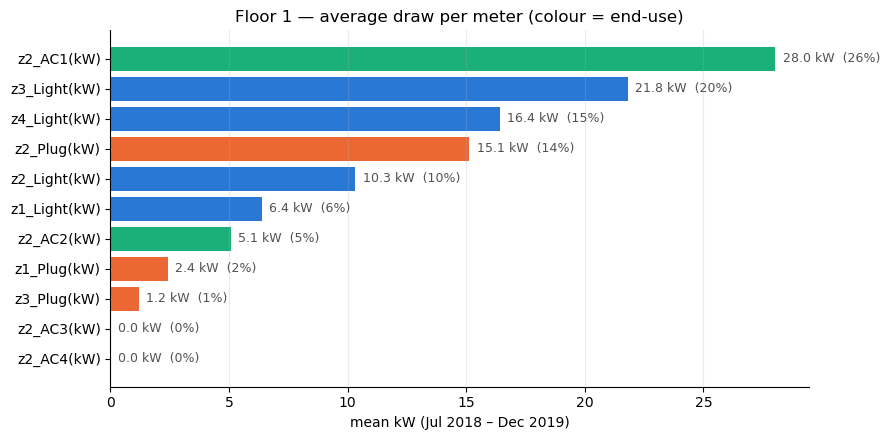

In [24]:
# Average draw per meter over the whole period, as a horizontal bar chart (biggest at the top)
share = df[POWER_COLS].mean().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [C[schema.loc[c, 'category']] for c in share.index]   # colour each bar by its end-use category
ax.barh(share.index, share.values, color=colors)
for i, v in enumerate(share.values):                            # write 'x kW (y%)' at the end of each bar
    ax.text(v + 0.3, i, f'{v:.1f} kW  ({v / share.sum():.0%})', va='center', fontsize=9, color='#52514e')
ax.set_xlabel('mean kW (Jul 2018 – Dec 2019)')
ax.set_title('Floor 1 — average draw per meter (colour = end-use)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [25]:
# Same idea, rolled up two ways: by zone (z1..z4) and by end-use (Light/Plug/AC)
zone_kw = df[POWER_COLS].mean().groupby(schema['zone']).sum()   # sum the meters' means within each zone
cat_kw = df[['Light', 'Plug', 'AC']].mean()                      # category totals built in section 5
# display() shows both tables (a cell otherwise only shows its last result); share formatted as a percentage
display(pd.DataFrame({'mean kW': zone_kw.round(1), 'share': (zone_kw / zone_kw.sum()).map('{:.0%}'.format)}))
display(pd.DataFrame({'mean kW': cat_kw.round(1), 'share': (cat_kw / cat_kw.sum()).map('{:.0%}'.format)}))

,mean kW,share
zone,,
z1,8.8,8%
z2,58.6,55%
z3,23.0,22%
z4,16.4,15%


,mean kW,share
Light,55.0,52%
Plug,18.6,17%
AC,33.1,31%


## 9. HVAC (AC) behaviour

In [26]:
# Only AC1 and AC2 ever meaningfully run. How often is each one on, alone or together?
ON = 1.0                                                   # treat a unit drawing > 1 kW as "running"
ac_on = df[['z2_AC1(kW)', 'z2_AC2(kW)']].gt(ON)            # True/False per minute per unit

# Build a text label per minute, e.g. 'AC1' + '+AC2' = 'AC1+AC2', then rename to readable states
state = (ac_on['z2_AC1(kW)'].map({True: 'AC1', False: ''}) + ac_on['z2_AC2(kW)'].map({True: '+AC2', False: ''})) \
    .replace({'': 'both off', '+AC2': 'AC2 only', 'AC1': 'AC1 only', 'AC1+AC2': 'both on'})
state.value_counts(normalize=True).mul(100).round(1).rename('% of minutes').to_frame()   # % of time in each state

,% of minutes
AC1 only,58.3
both off,23.0
both on,15.3
AC2 only,3.4


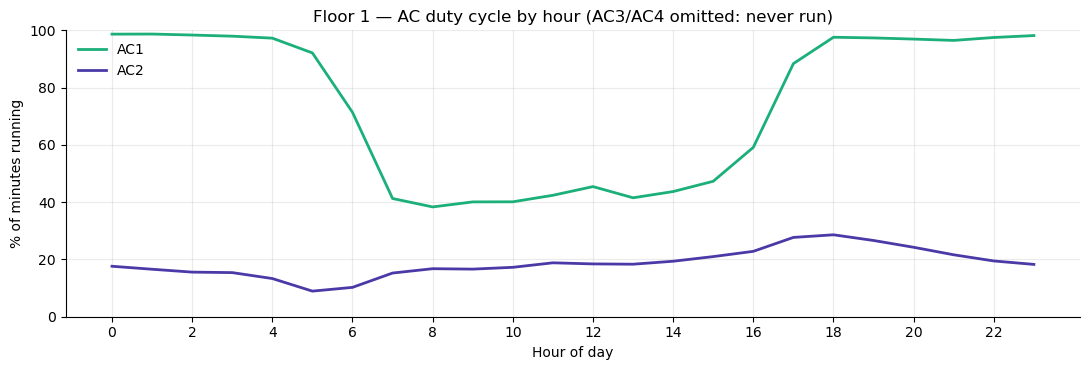

In [27]:
# Duty cycle = % of minutes a unit is running, averaged for each hour of the day
duty = ac_on.groupby(ac_on.index.hour).mean() * 100
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(duty.index, duty['z2_AC1(kW)'], color=C['AC'], linewidth=2, label='AC1')
ax.plot(duty.index, duty['z2_AC2(kW)'], color='#4a3aa7', linewidth=2, label='AC2')
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('Hour of day'); ax.set_ylabel('% of minutes running')
ax.set_ylim(0, 100); ax.legend(frameon=False)
ax.set_title('Floor 1 — AC duty cycle by hour (AC3/AC4 omitted: never run)')
plt.tight_layout(); plt.show()

In [28]:
# Duty cycle per month: does AC2 switch on more in the hot season (a "booster" unit)?
# Column names are renamed from 'z2_AC1(kW)' to 'z2_AC1 % on'; .T puts months across the top
ac_on.resample('MS').mean().mul(100).round(1).rename(columns=lambda c: c.replace('(kW)', ' % on')).T

Date,2018-07-01,2018-08-01,2018-09-01,2018-10-01,2018-11-01,2018-12-01,2019-01-01,2019-02-01,2019-03-01,2019-04-01,2019-05-01,2019-06-01,2019-07-01,2019-08-01,2019-09-01,2019-10-01,2019-11-01,2019-12-01
z2_AC1 % on,76.4,71.1,73.1,73.5,66.4,77.1,73.4,74.0,70.6,75.1,74.4,77.5,70.8,75.3,73.0,74.0,71.8,77.1
z2_AC2 % on,30.9,30.3,18.0,14.2,14.0,13.8,17.6,14.8,15.0,31.2,42.9,34.9,20.3,14.2,4.6,11.4,4.7,3.4


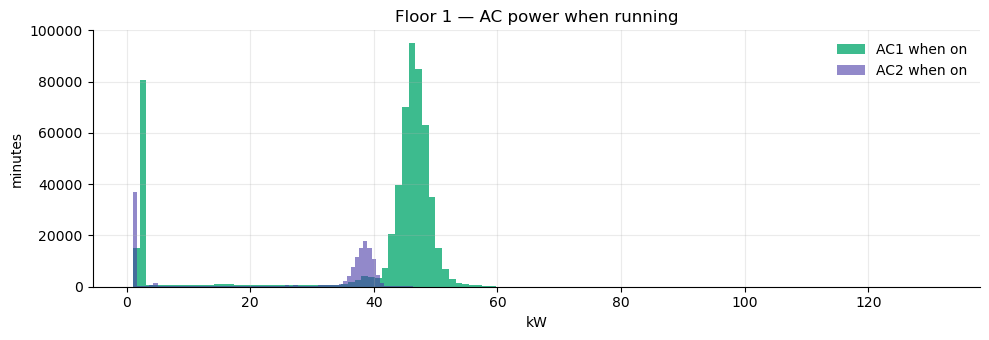

In [29]:
# How much power does each unit draw WHILE it's running? (histogram of the 'on' readings only)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(df.loc[ac_on['z2_AC1(kW)'], 'z2_AC1(kW)'], bins=120, color=C['AC'], alpha=.85, label='AC1 when on')
ax.hist(df.loc[ac_on['z2_AC2(kW)'], 'z2_AC2(kW)'], bins=120, color='#4a3aa7', alpha=.6, label='AC2 when on')
ax.set_xlabel('kW'); ax.set_ylabel('minutes'); ax.legend(frameon=False)
ax.set_title('Floor 1 — AC power when running')
plt.tight_layout(); plt.show()

## 10. Year-over-year shifts

In [30]:
# Fair comparison: only Jul–Dec exists for 2018, so compare Jul–Dec 2018 with Jul–Dec 2019
h2 = df[df.index.month >= 7]                                                  # keep months 7..12 only
yoy = h2.groupby(h2.index.year)[POWER_COLS + ['Light', 'Plug', 'AC', 'Total']].mean().T   # mean kW per year
yoy.columns = ['H2 2018 kW', 'H2 2019 kW']
yoy['change %'] = ((yoy['H2 2019 kW'] / yoy['H2 2018 kW'] - 1) * 100).round(1)   # negative = less power in 2019
yoy.round(2)

,H2 2018 kW,H2 2019 kW,change %
z1_Light(kW),6.39,7.13,11.6
z1_Plug(kW),4.18,1.45,-65.2
z2_AC1(kW),29.00,24.99,-13.8
z2_AC2(kW),4.76,3.36,-29.4
z2_AC3(kW),0.01,0.01,-18.9
z2_AC4(kW),0.01,0.01,-17.9
z2_Light(kW),14.75,7.10,-51.9
z2_Plug(kW),15.63,14.12,-9.7
z3_Light(kW),23.56,21.58,-8.4
z3_Plug(kW),1.16,1.20,3.1


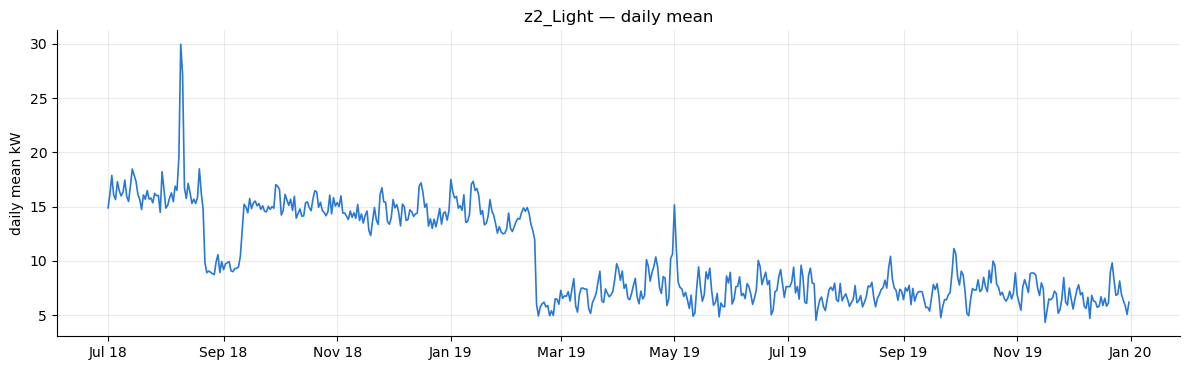

Most likely step change: week ending 2019-02-17  |  before ≈ 14.7 kW, after ≈ 7.3 kW


In [31]:
# z2_Light drops sharply at some point, so plot its daily mean to see it
z2l = df['z2_Light(kW)'].resample('D').mean()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(z2l.index, z2l, color=C['Light'])
ax.set_ylabel('daily mean kW'); ax.set_title('z2_Light — daily mean')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
plt.tight_layout(); plt.show()

# Simple change-point detection: try every week as a split point and pick the one where the mean
# before vs after differs the most. Weekly means are used so single noisy days don't dominate.
w = df['z2_Light(kW)'].resample('W').mean().dropna()
# score each candidate split i (skip the first/last 4 weeks so each side has enough data)
scores = {w.index[i]: abs(w.iloc[:i].mean() - w.iloc[i:].mean()) for i in range(4, len(w) - 4)}
cp = max(scores, key=scores.get)       # the week with the biggest before/after difference
print(f"Most likely step change: week ending {cp.date()}  |  "
      f"before ≈ {w[:cp].iloc[:-1].mean():.1f} kW, after ≈ {w[cp:].mean():.1f} kW")

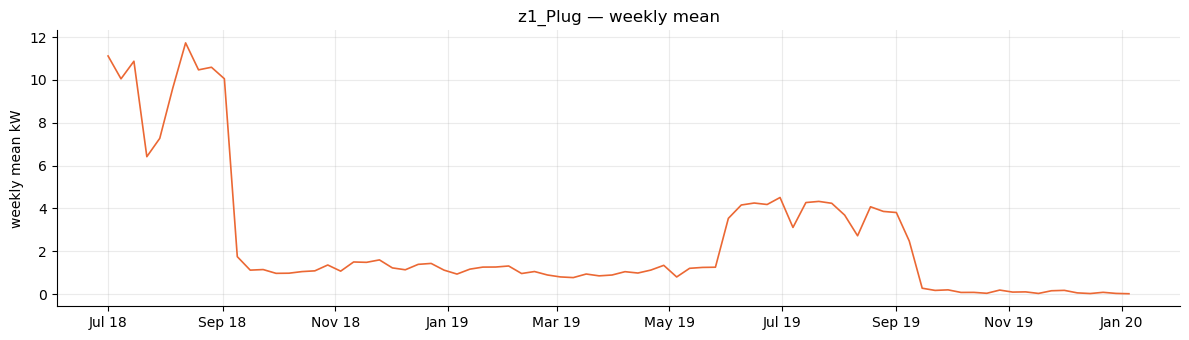

In [32]:
# z1_Plug also shifts: high in Jul–Aug each year, near zero from Oct 2019. Weekly means make the trend clear.
z1p = df['z1_Plug(kW)'].resample('W').mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(z1p.index, z1p, color=C['Plug'])
ax.set_ylabel('weekly mean kW'); ax.set_title('z1_Plug — weekly mean')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
plt.tight_layout(); plt.show()

## 11. Correlations

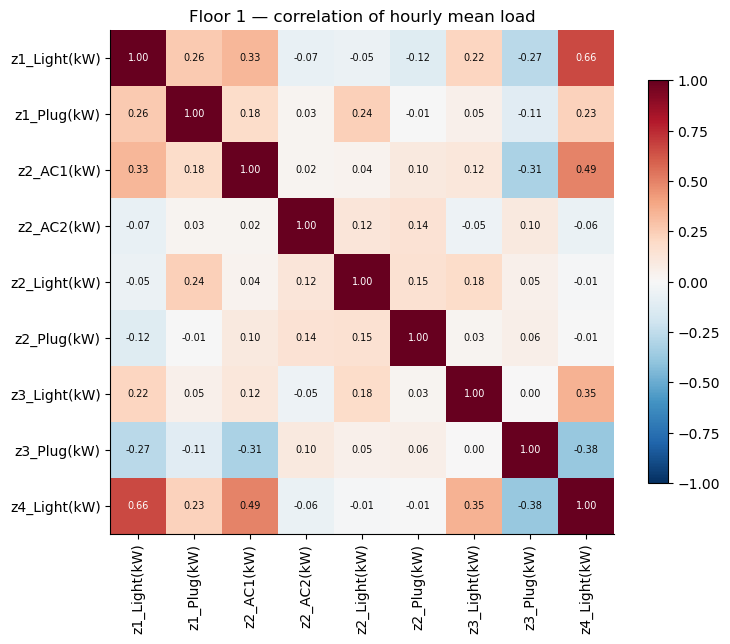

In [33]:
# Which meters rise and fall together? Correlate hourly averages (minute data is too noisy),
# leaving out the dead AC3/AC4 meters, which carry no signal
live = [c for c in POWER_COLS if c not in ('z2_AC3(kW)', 'z2_AC4(kW)')]
hourly = df[live].resample('h').mean()          # 'h' = group by hour
corr = hourly.corr()                            # Pearson r for every pair: +1 move together, −1 opposite, 0 unrelated

# Heatmap of the correlation matrix: red = positive, blue = negative, white = none
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(live)), live, rotation=90); ax.set_yticks(range(len(live)), live)
for i in range(len(live)):                      # write the r value in every cell
    for j in range(len(live)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr.iloc[i, j]) > .6 else '#0b0b0b')   # white text on dark cells
ax.grid(False); fig.colorbar(im, ax=ax, shrink=.8)
ax.set_title('Floor 1 — correlation of hourly mean load')
plt.tight_layout(); plt.show()

In [34]:
# List the strongest pairs. The matrix is symmetric (A-B = B-A), so keep only the upper triangle
# (np.triu, k=1 also drops the diagonal where each meter correlates 1.0 with itself), then sort by strength
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
pairs.head(8).round(2).rename('r').to_frame()

r
z1_Light(kW) z4_Light(kW)  0.66
z2_AC1(kW)   z4_Light(kW)  0.49
z3_Plug(kW)  z4_Light(kW) -0.38
z3_Light(kW) z4_Light(kW)  0.35
z1_Light(kW) z2_AC1(kW)    0.33
z2_AC1(kW)   z3_Plug(kW)  -0.31
z1_Light(kW) z3_Plug(kW)  -0.27
             z1_Plug(kW)   0.26

## 12. Findings summary & next steps

**Data structure**
- 790,560 rows (Jul 2018 – Dec 2019), perfectly regular 1-minute timeline; both files share the same 11 power meters.
- Floor 1 has **power only**: 4 lighting zones (z1–z4), 3 plug zones (z1–z3), 4 AC units (all in z2). No temperature, humidity or lux.

**Data quality**
- Missingness is low (<0.6%) except **z2_Plug: a ~20-day outage, 22 Aug – 11 Sep 2018** (11% of 2018). Don't interpolate it.
- 67 logger-wide outage blocks (all meters NaN), longest ≈ 5 h (17 Aug 2018) and ≈ 4.5 h (12–13 Jul 2019).
- A few order-of-magnitude single-minute glitches (z3_Light 4,762 kW, z2_AC2 798 kW, z4_Light 512 kW, z2_AC3 25 kW) → removed.
- **z2_AC3 and z2_AC4 never run** (~0.01 kW 99.7% of the time): dead or unused units, so exclude them from modelling.
- **28–31 Aug 2018**: sustained, simultaneous high load on lighting, z1_Plug and AC1. Looks like a real event, not noise; flag it when building a baseline.
- ⚠️ **Timestamps look ~7 h ahead of local time** (section 7). This affects every hour-of-day / weekday result.

**Consumption**
- Average floor draw ≈ 107 kW. **Lighting is the largest end-use (~52%)**, then AC (~31%), plugs (~17%).
- Zone 2 dominates (~55%) because it holds all the AC plus the biggest plug load.
- Monthly energy ranges ~66–98 MWh; peaks in Jul–Aug 2018 and May 2019 (AC-driven; hottest months in Bangkok).
- **AC1 is the workhorse** (on ~73% of minutes, ~45 kW when on); **AC2 is a supplementary unit** that runs more in hot months
  (30–43% of minutes in Apr–May, <5% in Nov–Dec 2019).

**Year-over-year (Jul–Dec 2018 vs Jul–Dec 2019): total load −17%**
- **z2_Light dropped ~52% as a step change around mid-Feb 2019** (≈14.7 → 7.3 kW). Looks like a retrofit (e.g. LED) or a schedule change, which makes it a clean natural experiment for a savings/baseline question.
- **z1_Plug fell ~65%** and is near zero from Oct 2019. Equipment may have been removed or the space vacated.
- AC is also down ~16% (AC2 used much less in late 2019).

**Correlations (hourly)**
- Weak overall. The strongest is z1_Light ↔ z4_Light (r ≈ 0.66), and AC1 tracks z4_Light (r ≈ 0.49), suggesting a shared occupancy schedule.

**Possible project directions from Floor 1**
1. Measurement & verification: quantify savings from the Feb 2019 z2_Light step change against a pre-change baseline.
2. Anomaly detection: the Aug 2018 event, spikes and outages are useful labelled examples.
3. Load forecasting of AC1 / total load (seasonality + weekly schedule), once the timestamp question is settled.

**Next steps**
- [ ] Compare the timestamp inversion with the other floors (group decision on a correction)
- [ ] Check whether a retrofit on Floor 1 around Feb 2019 is documented anywhere
- [ ] Pull outdoor weather (Bangkok temperature) to explain AC seasonality, since Floor 1 has no indoor temp sensor